# SafeFlow final comparative results

This is the finalized evidence showcase, not a declaration of one final model. All three models are retained; boosted trees and Transformer are the leading candidates. Neither leading candidate satisfies the target warning budget on holdout, while both demonstrate predictive feasibility of the proposed target. Improvements and retraining require new independent evaluation.

The default execution regenerates figures, checks the saved model bundles, and reproduces all nine frozen holdout policy rows. It does not fit new models or tune thresholds. A separate optional cell runs the full raw-data training replay, which can take hours. Historical six-fold comparisons are preserved source-backed evidence; unavailable historical feature snapshots prevent reconstructing every original historical fit.


In [1]:
from pathlib import Path
import sys, json, warnings
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'configs/evaluation.yaml').is_file())
sys.path.insert(0,str(ROOT))
# Initialize Torch before Arrow/threadpool native DLLs on Windows.
import torch
import pandas as pd
from IPython.display import display, Image
from src.analysis.study_release import config
from src.analysis.release_reporting import generate
from src.analysis.release_verification import verify
warnings.filterwarnings('ignore',category=FutureWarning)
CFG=config()
RESULTS=ROOT/CFG['release']['results']
print('Kernel:',sys.executable)
print('Study:',CFG['study'],'| selected final model:',CFG['selected_final_model'])


Kernel: C:\Users\abhis\anaconda3\envs\erdos_ds_environment\python.exe
Study: safeflow_comparative_release | selected final model: None


## Problem, stakeholders and data

For every station every five minutes, predict whether speed will be strictly below 40 mph at any of the next six readings (30 minutes). Traffic management center operators and transportation agencies are potential users; the study measures prediction and warning burden, not reductions in congestion caused by interventions.

The current cohort is 46 D12 I-5 mainline stations. Forecast origins are 06:00-19:55 on weekdays excluding federal holidays. Training/scoring require known future outcomes where appropriate. The held-out period contains 966,000 rows, 636,806 known outcomes, 556,199 primary-AP-eligible origins, and 3,497 onsets across 125 days. One expected business day, November 28, is missing. D7 generalization is not established.

## Warning policy and budget: read before the plots

A **warning policy** is an alerting rule: issue a warning when predicted probability reaches a threshold. Each model has its own threshold chosen using calibration data and frozen before testing. This is not a traffic-control policy.

A **budget** is an illustrative target for false-warning burden used during threshold selection, not money or a hard guarantee on future data. A continuous 30-minute wrong warning is **one episode and 0.5 hours**; six separated five-minute wrong warnings are **six episodes and 0.5 hours**. Simultaneous detector warnings add to corridor duration separately.

- Duration policy: maximize early onset detection under a calibration target of 4 wrong-alert hours/day.
- Episode policy: maximize early detection under a calibration target of 20 false-warning episodes/day.
- Fixed 0.5: a diagnostic score threshold without budget optimization.

Circles, squares and triangles in the original tradeoff plot denote duration, episode and fixed-0.5 policies; color denotes model. Equal calibration targets are not identical realized costs. All three models exceed both types of target on holdout.


## Shared features and modeling journey

The 29 logical features cover current speed/flow/occupancy, recent changes, upstream/downstream conditions, ramp flows, time and training-only typical patterns. Feature selection and earlier group-ablation evidence are preserved in the archived research analyses. The initial selected core and subsequent additions should not be described as if all 29 were individually proven necessary by the holdout.

Timetable estimates recurring congestion as a baseline. Random Forest captures nonlinear tabular interactions through bagged trees; boosted trees sequentially improve tabular predictions; Transformer tests additional historical sequence information. The feature names are shared but sequence inputs are not identical. Prior endpoint/horizon experiments used different targets and are not directly comparable final scores.

Core engineering replaced raw time with cyclic encoding, represented local/neighbor conditions as anomalies or differences, and dropped redundant upstream/downstream occupancy. Later additions reintroduced raw measurements and extra histories; the original low-correlation rationale is not a property of all 29 features. [Feature decisions and historical evidence](../results/final/development/feature_engineering.md) and [ordered schema](../results/final/development/feature_schema.csv).


In [2]:
import yaml
for model in CFG['models']:
    recipe=yaml.safe_load((ROOT/'configs/models'/f'{model}.yaml').read_text())
    print(model,recipe)


random_forest {'name': 'random_forest', 'seed': 42, 'parameters': {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 10, 'max_samples': 0.25}, 'preprocessing': 'training-only median imputation, missing indicators, weekday one-hot encoding'}
boosted_trees {'name': 'boosted_trees', 'seed': 0, 'parameters': {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'early_stopping': False}, 'preprocessing': 'native missing-value handling; numeric weekday'}
transformer {'name': 'transformer', 'seed': 42, 'lookback': 24, 'epochs': 10, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 0.01, 'device': 'cpu', 'parameters': {'d_model': 64, 'nhead': 4, 'num_layers': 2, 'd_ff': 128, 'dropout': 0.1}, 'preprocessing': 'training-only medians and scaling, weekday encoding, missing indicators, gap-aware history padding'}


## Recorded training and evaluation protocol

The packaged checkpoints were fitted on the same two-million-endpoint sample, with training target windows ending before March 25, 2025. April-June predictions calibrate the thresholds. July-December is the already-evaluated holdout. No refit through June or holdout-based tuning occurred.

The executable training path calls the recorded factories, training-only preprocessing and model workers. It is controlled by the versioned configuration. Full replay rebuilds features from raw data, fits all models, calibrates and evaluates the fixed protocol, then generates reports in a new workspace. It preserves the original release and does not constitute another independent test.


In [3]:
REBUILD_MODELS = False  # Full raw-data replay can take hours; off for the report showcase.
if REBUILD_MODELS:
    from src.analysis.release_pipeline import replay
    replay_root=replay(use_cache=False)
    RESULTS=replay_root/'release'
else:
    print('Using packaged evaluated checkpoints; no training or threshold tuning.')


Using packaged evaluated checkpoints; no training or threshold tuning.


## Portable checkpoint verification

Each retained model has a checkpoint, preprocessing, ordered feature schema, frozen typical-feature statistics, spatial mappings and threshold metadata. This check loads the packaged bundles and reproduces fixed development probabilities without the original run directories or raw data. Targets carried in the fixture are not model inputs.


In [4]:
display(pd.DataFrame(verify()))


,model,endpoints,max_probability_error,tolerance,training_feature_statistics_reproduce
0,transformer,48,0.000000e+00,1.000000e-05,True
1,random_forest,48,5.551115e-16,1.000000e-10,True
2,boosted_trees,48,0.000000e+00,1.000000e-10,True


## Regenerate metrics and figures

AP ranks outcomes on measured, currently uncongested origins with known futures; it is not onset-event recall. Early detection asks whether a warning preceded an onset by 15-30 minutes. Brier score measures probability error. Wrong-warning duration and episode counts capture different operational burdens.

The command below verifies every regenerated score against the saved frozen tables. Reliability plots describe the fixed probabilities; no calibrator is fitted on the holdout.


In [5]:
generate(output=RESULTS,source=RESULTS)
metrics=pd.read_csv(RESULTS/'recomputed_holdout_metrics.csv')
print('Primary warning comparison: duration policy, target 4 wrong-alert hours/day on calibration data')
display(metrics.loc[metrics.policy.eq('duration')].round(4))
print('Secondary policies: episode target and diagnostic threshold 0.5')
display(metrics.loc[metrics.policy.ne('duration')].round(4))


Generated final report figures and reproduced all 9 holdout metric rows: C:\Erdos\Project\safeflow\results\final
Primary warning comparison: duration policy, target 4 wrong-alert hours/day on calibration data


,model,policy,threshold,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
1,Random Forest,duration,0.5109,0.7216,0.9645,0.0248,0.4392,32.208,4.8073,0.9268,15.0,3497
4,Boosted trees,duration,0.5435,0.7412,0.9677,0.0238,0.5433,30.856,4.8687,0.9267,20.0,3497
7,Transformer,duration,0.5834,0.7380,0.9669,0.0240,0.5668,28.880,4.9660,0.9254,20.0,3497


Secondary policies: episode target and diagnostic threshold 0.5


,model,policy,threshold,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
0,Random Forest,episodes,0.6900,0.7216,0.9645,0.0248,0.2190,21.672,2.4440,0.9588,10.0,3497
2,Random Forest,default_0.5,0.5000,0.7216,0.9645,0.0248,0.4527,32.712,4.9947,0.9245,15.0,3497
3,Boosted trees,episodes,0.6690,0.7412,0.9677,0.0238,0.4055,23.216,3.1873,0.9489,15.0,3497
5,Boosted trees,default_0.5,0.5000,0.7412,0.9677,0.0238,0.5819,33.904,5.5813,0.9178,20.0,3497
6,Transformer,episodes,0.6839,0.7380,0.9669,0.0240,0.4744,23.424,3.6113,0.9430,20.0,3497
8,Transformer,default_0.5,0.5000,0.7380,0.9669,0.0240,0.6237,33.648,6.2073,0.9102,22.5,3497


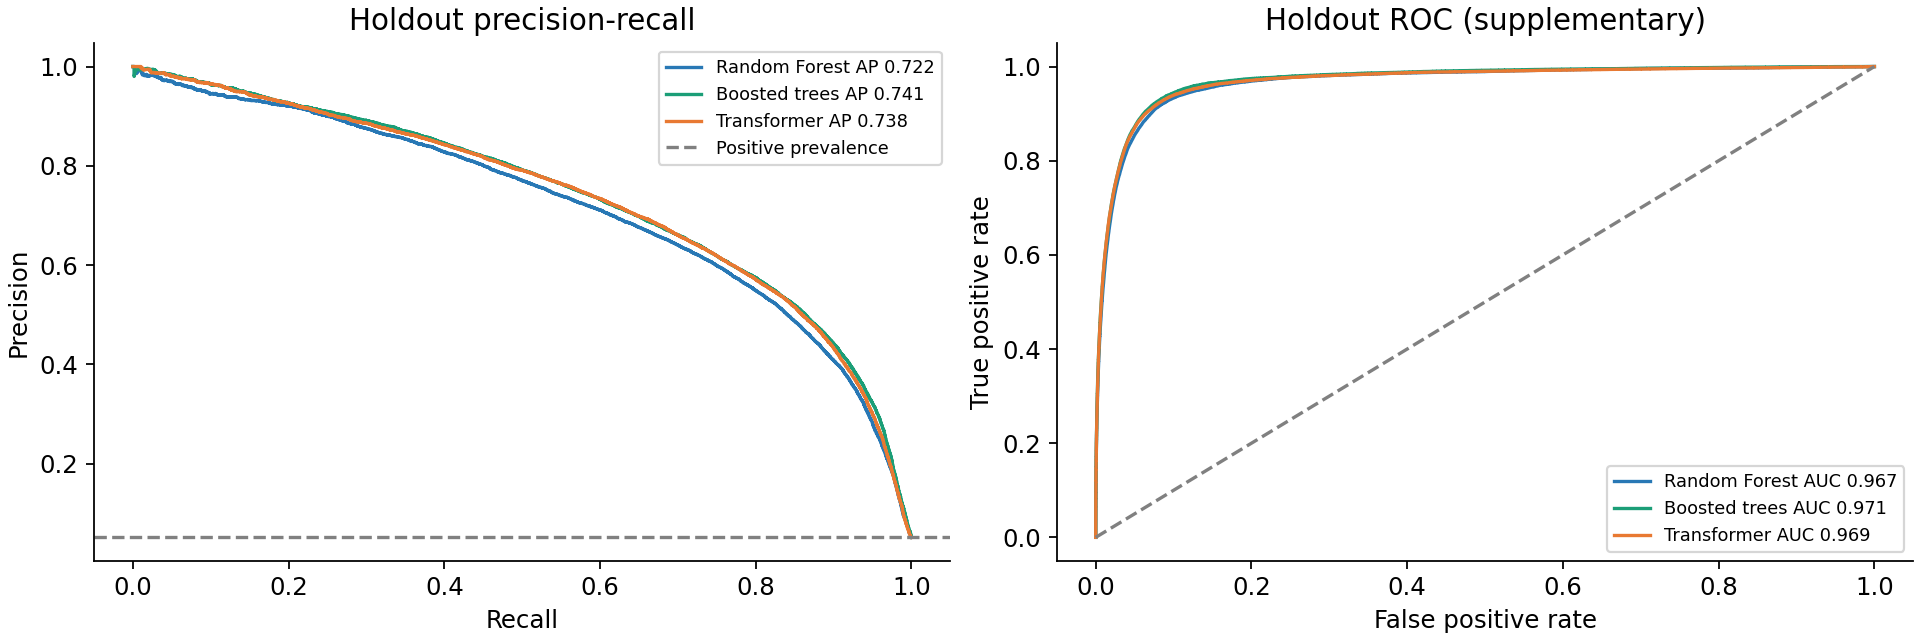

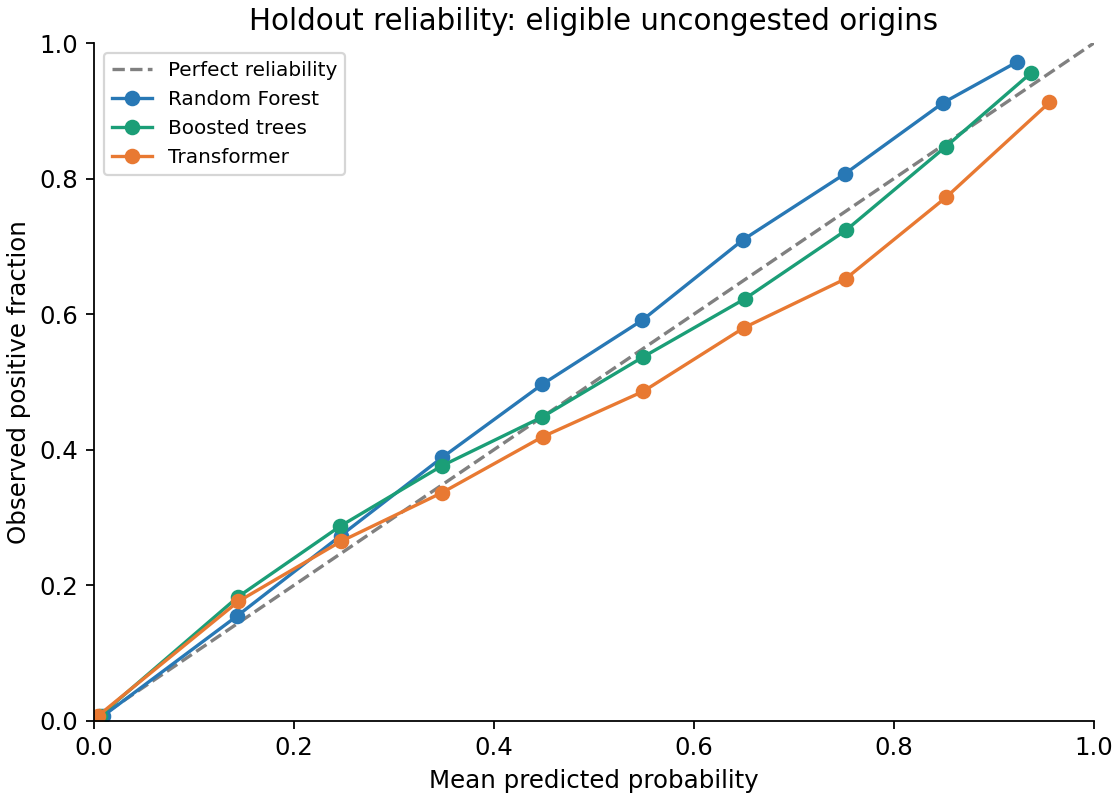

In [6]:
display(Image(filename=str(RESULTS/'figures/holdout_ranking.png')))
display(Image(filename=str(RESULTS/'figures/holdout_calibration.png')))


## Operational errors and budget transfer

Every duration policy exceeds 4 wrong-alert hours/day on holdout; every episode policy exceeds 20 false episodes/day. These are observed breaches, not corrected by choosing new thresholds after testing. Non-recurrent onsets are those whose training-only usual congestion rate 15 minutes before onset is below 10%; this is not a crash/incident-cause label.

The paired weekly duration-policy comparison favors Transformer for early catch over boosted trees by 2.34 percentage points (95% interval +1.19 to +3.49). Its wrong-alert duration is slightly higher, with the difference interval spanning zero. These are not exactly matched-cost operating points, and the intervals condition on saved fits and thresholds.


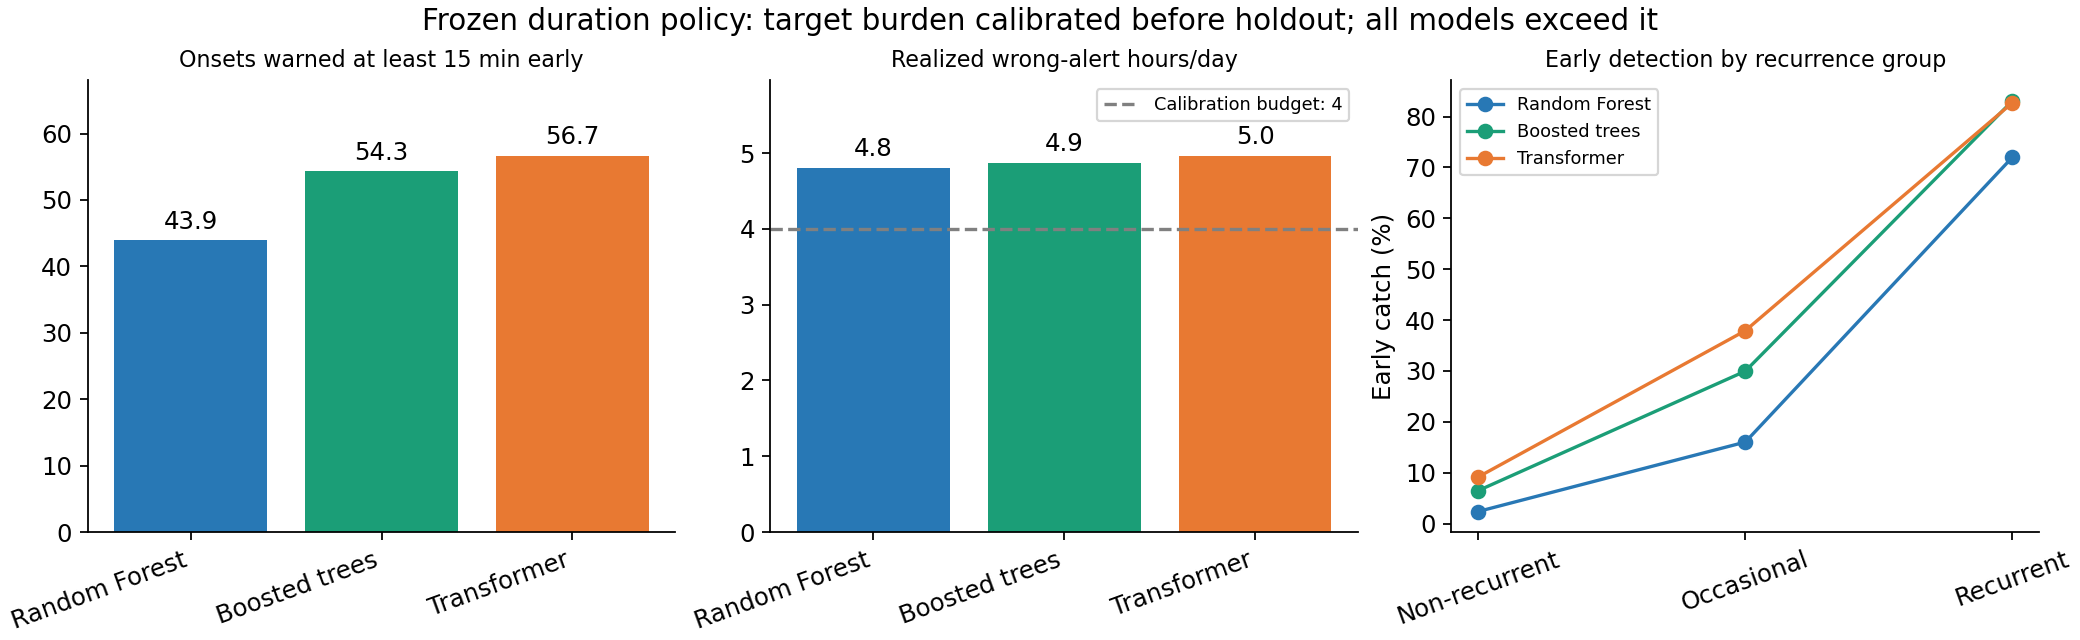

,model_a,model_b,metric,block,difference,ci_low,ci_high,blocks,repetitions,seed
0,Transformer,Boosted trees,catch_15min,week,0.0234,0.0119,0.0349,28,5000,42
1,Transformer,Boosted trees,false_episodes_per_day,week,-1.9760,-2.5433,-1.3710,28,5000,42
2,Transformer,Boosted trees,wrong_alert_hours_per_day,week,0.0973,-0.0525,0.2825,28,5000,42
3,Transformer,Boosted trees,rare_catch_15min,week,0.0268,0.0072,0.0445,28,5000,42


In [7]:
display(Image(filename=str(RESULTS/'figures/holdout_errors_and_budget.png')))
display(pd.read_csv(RESULTS/'holdout/paired_duration_intervals.csv').round(4))


## Historical development evidence and local operating cost

The six-fold table is historical published evidence, separate from the single frozen-checkpoint holdout. It is not recomputed training from an unavailable historical feature snapshot. The benchmark uses the current shared source and full-size last-fold fits. Transformer has low warm small-batch latency but much longer training time; boosted trees have stronger bulk fixture throughput. Process RSS includes dependencies and inputs; these are measurements on one machine, not deployment guarantees.


,model,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
0,boosted_trees,2026-11-04,29,0.7666,0.0110,0.7552,0.0220,0.6395,31.0961,5.0443
1,transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
2,random_forest_shared_29_features,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619


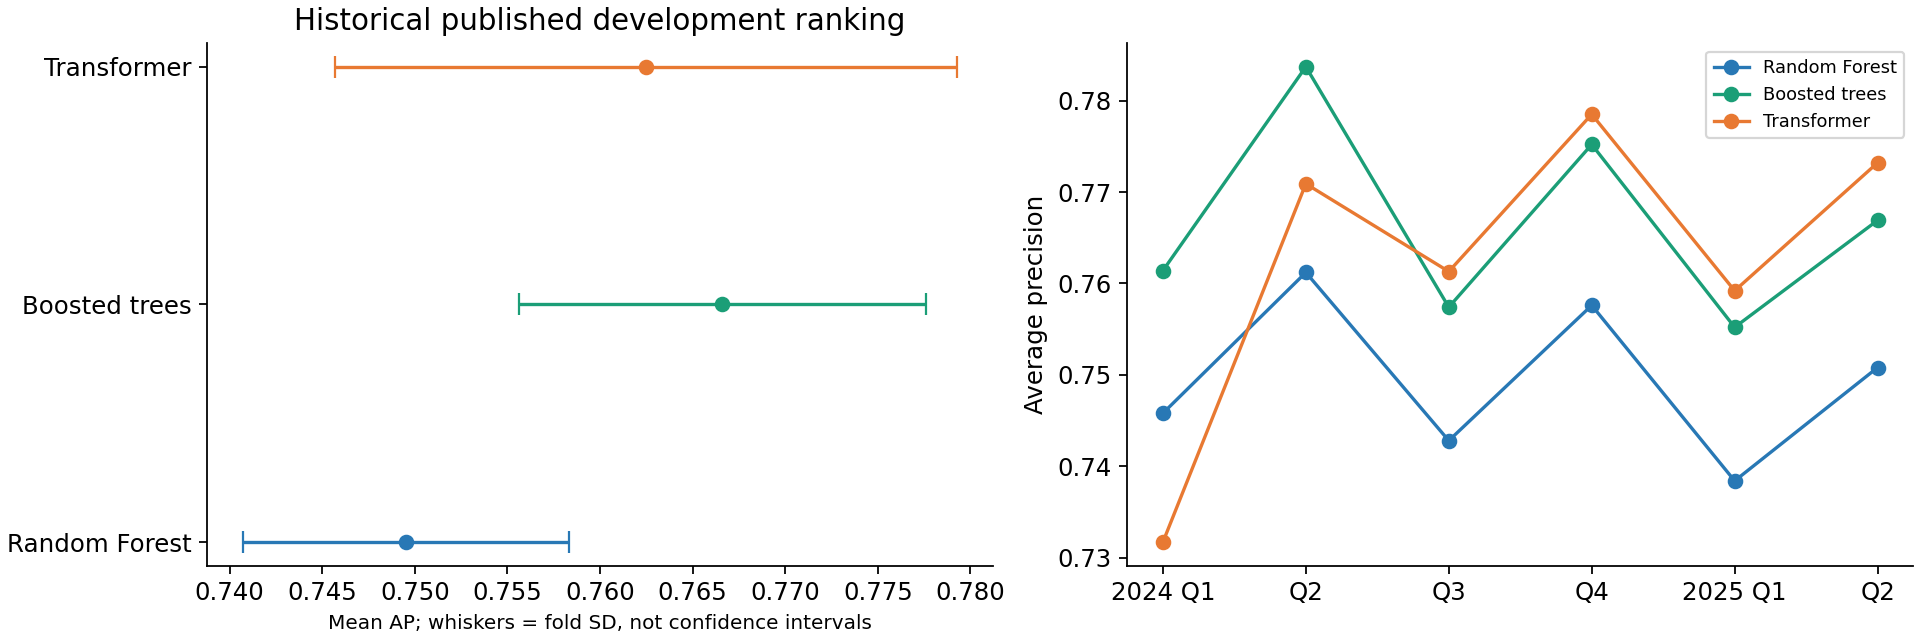

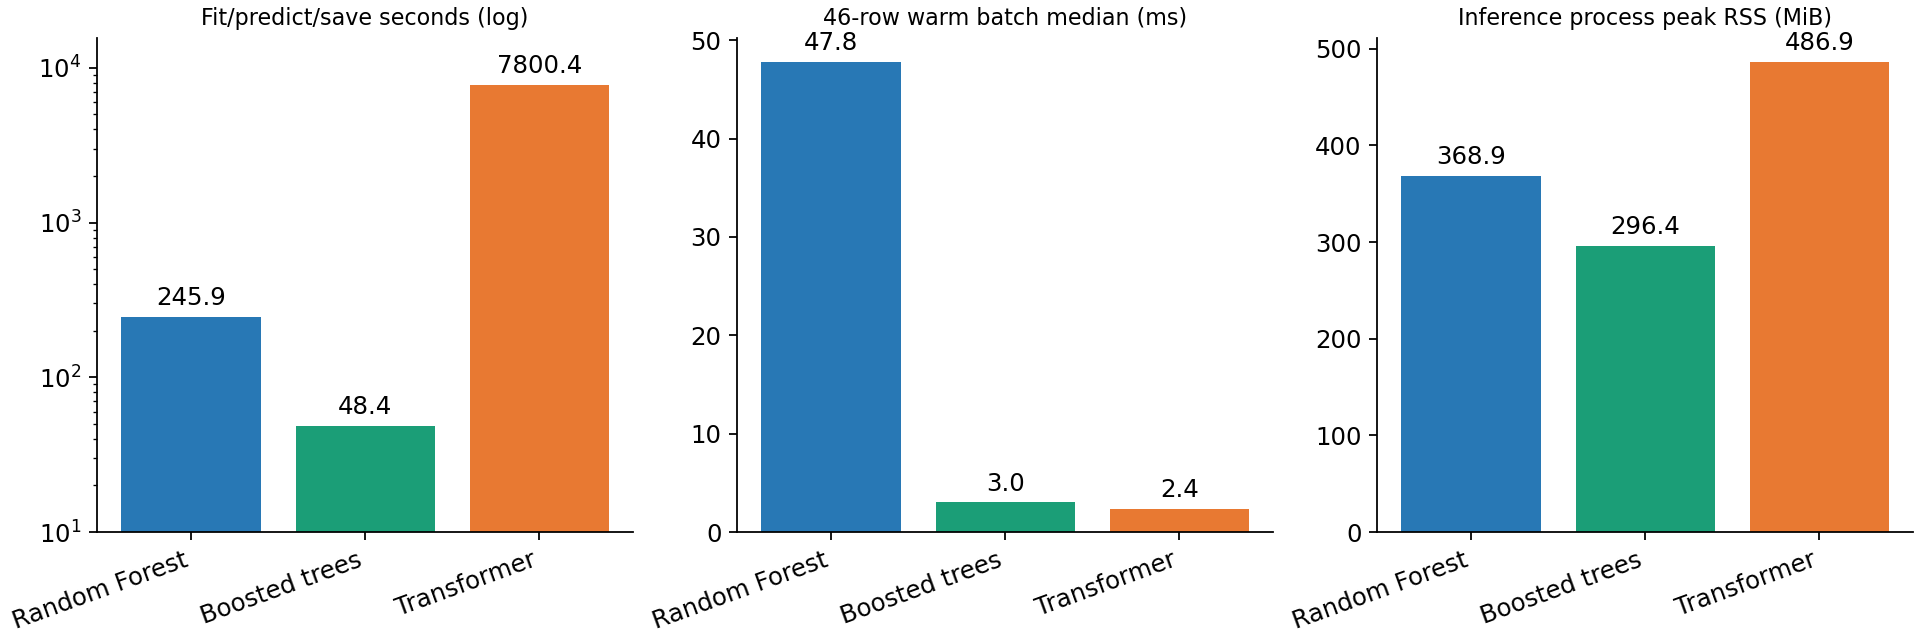

In [8]:
display(pd.read_csv(RESULTS/'development/summary.csv'))
display(Image(filename=str(RESULTS/'figures/development_ranking.png')))
display(Image(filename=str(RESULTS/'figures/operational_benchmark.png')))


## Conclusion and next steps

All three models remain in the repository. Boosted trees and Transformer are the leading candidates, and neither is designated the final model. Both demonstrate predictive feasibility of the target design, but neither meets the intended holdout warning budget. Further improvements, additional data and retraining may help; they are not proven remedies and require new independent validation.

Scope limitations include one D12 cohort, unusual-onset failures, the historical Transformer feature-source mismatch, and diagnostic feature masking that does not simulate raw detector outages causally. Operational benefit from acting on alerts is not measured.

See [the executive summary](../presentation/summary.md), [data documentation](../data/README.md), [KPI definitions](../kpis.md) and [artifact documentation](../artifacts/README.md). Slides are supplied manually. All figures displayed here are generated by versioned code from the curated evidence.
